### 🧠 Query Planning & Decomposition (Groq + HuggingFace)
- **Planner**: breaks a complex question into self-contained sub-questions (structured output)
- **Retriever**: retrieves docs per sub-question in parallel, de-duplicates them
- **Responder**: answers using context grouped by sub-question, then synthesizes one final answer

In [10]:
import os
from dotenv import load_dotenv, find_dotenv

# .env sits in the repo root, one level above this notebook
load_dotenv(find_dotenv(usecwd=True), override=True)

# .env stores the keys in lowercase; ChatGroq and huggingface_hub read the uppercase names
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY") or os.getenv("groq_api", "")
os.environ["HF_TOKEN"] = os.getenv("HF_TOKEN") or os.getenv("hf_token", "")
assert os.environ["GROQ_API_KEY"], "groq_api / GROQ_API_KEY missing in .env"

# Removes the WebBaseLoader warning (must be set before langchain_community is imported)
os.environ.setdefault("USER_AGENT", "rag-learning-notebook/1.0")
print("GROQ_API_KEY loaded:", os.environ["GROQ_API_KEY"].startswith("gsk_"))

GROQ_API_KEY loaded: True


In [11]:
from typing import List, Dict
from pydantic import BaseModel, Field

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import WebBaseLoader
from langchain_community.vectorstores import FAISS

from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import StateGraph, END

In [12]:
# llama-3.3-70b-versatile is no longer served by Groq (404 model_not_found)
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0)

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [13]:
urls = [
    "https://lilianweng.github.io/posts/2023-06-23-agent/",
    "https://lilianweng.github.io/posts/2024-04-12-diffusion-video/",
]

docs = WebBaseLoader(urls).load()

splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
chunks = splitter.split_documents(docs)

vectorstore = FAISS.from_documents(chunks, embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 4})
print(f"Pages: {len(docs)} | Chunks indexed: {len(chunks)}")

Pages: 2 | Chunks indexed: 234


In [14]:
class RAGState(BaseModel):
    question: str
    sub_questions: List[str] = []
    docs_per_subq: Dict[str, List[Document]] = {}   # keeps which docs belong to which sub-question
    answer: str = ""


class QueryPlan(BaseModel):
    sub_questions: List[str] = Field(
        description="2-4 self-contained sub-questions. Each one must make sense on its own."
    )

planner_llm = llm.with_structured_output(QueryPlan)

In [15]:
## a. Query Planner
def plan_query(state: RAGState):
    prompt = f"""Break the question below into 2-4 simple, self-contained sub-questions for document search.

Rules:
- If the question asks about several independent topics, keep them separate.
- Do NOT invent connections between topics that the user did not ask about.
- Do not number the sub-questions.

Question: {state.question}"""
    plan: QueryPlan = planner_llm.invoke(prompt)
    subs = [q.strip() for q in plan.sub_questions if q.strip()]
    print("🧩 Sub-questions:", *subs, sep="\n  - ")
    return {"sub_questions": subs}


## b. Retrieve for each sub-question (parallel + de-duplicated)
def retrieve_for_each(state: RAGState):
    results = retriever.batch(state.sub_questions)   # runs the searches in parallel

    seen = set()
    docs_per_subq = {}
    for subq, docs in zip(state.sub_questions, results):
        unique = []
        for d in docs:
            if d.page_content not in seen:
                seen.add(d.page_content)
                unique.append(d)
        docs_per_subq[subq] = unique
        print(f"🔎 {len(unique)} new docs for: {subq}")
    return {"docs_per_subq": docs_per_subq}


## c. Generate final answer (context grouped by sub-question)
def generate_final_answer(state: RAGState):
    sections = []
    for subq, docs in state.docs_per_subq.items():
        body = "\n\n".join(d.page_content for d in docs) or "(no new documents)"
        sections.append(f"### Sub-question: {subq}\n{body}")
    context = "\n\n".join(sections)

    prompt = f"""Answer the user's question using ONLY the context below.
The context is grouped by sub-question. Cover every sub-question, then give a short combined summary.
If the context does not cover something, say so instead of guessing.

{context}

User question: {state.question}"""
    answer = llm.invoke(prompt).content.strip()
    return {"answer": answer}

In [16]:
builder = StateGraph(RAGState)

builder.add_node("planner", plan_query)
builder.add_node("retriever", retrieve_for_each)
builder.add_node("responder", generate_final_answer)

builder.set_entry_point("planner")
builder.add_edge("planner", "retriever")
builder.add_edge("retriever", "responder")
builder.add_edge("responder", END)

graph = builder.compile()

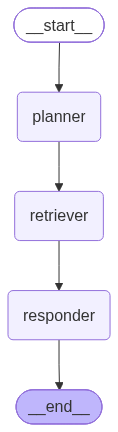

In [17]:
from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Diagram render failed (needs internet):", e)

In [18]:
user_query = "Explain how agent loops work and what are the challenges in diffusion video generation?"
final_state = graph.invoke(RAGState(question=user_query))

print("\n🔍 Sub-questions:")
for q in final_state["sub_questions"]:
    print("-", q)

print("\n✅ Final Answer:\n", final_state["answer"])

🧩 Sub-questions:
  - How do agent loops work?
  - What are the challenges in diffusion video generation?
🔎 4 new docs for: How do agent loops work?
🔎 4 new docs for: What are the challenges in diffusion video generation?

🔍 Sub-questions:
- How do agent loops work?
- What are the challenges in diffusion video generation?

✅ Final Answer:
 **How agent loops work**

1. **Planning for believability** – An agent’s plan is crafted to make its actions look plausible at the moment while also considering future states.  
2. **Observations & relationships** – Each agent observes other agents and the environment. These observations, along with the relationships between agents, feed into the planning and reaction stages.  
3. **Tree‑structured environment** – The environment’s information is organized as a tree, allowing the agent to reason about nested or hierarchical states.  
4. **Learning history concatenation** – After each action, the agent records its experience. The learning history (AD) 